## Libraries

In [2]:
import os

In [3]:
run = 'local' #local or cloud
os.environ["APP_ENV"] = run

In [4]:
import sys
sys.path.append('..')

In [5]:
from src.core_grass import*
%matplotlib inline
#%load_ext autoreload
#%autoreload 2

In [6]:
import subprocess
result = subprocess.run(["grass", "--config", "python_path"],
                        check=True, text=True, capture_output=True)
sys.path.append(result.stdout.strip())

# import GRASS Python packages
from collections import defaultdict
import grass.script as gs
import grass.jupyter as gj

# Parameters

In [7]:
#set project variables
Project_Area = 'glen_prov'
projection = '2272' #set to None if you want to use the DEM's original projection
res = '1m'

## Set variables analysis
source = 'wbd' #wbd or user-defined
data_scale = 'HUC12' #other options HUC12, HUC10, HUC8 OR the field name of the source data to be split <-- case sensitive
select_data = '020402020602' #     # Value within the filter_field used for data selection 
to_headwaters = False #False if only interested in local huc area
input_shp_name = None #None or must be populated populated with a shapefile polygons if data_scale != HUCXX
buffer = 2000
auto_delete = False

In [8]:
if data_scale.find('HUC') >= 0:
    huc_level = re.findall("[0-9]+",data_scale)[0]
    if huc_level == str(len(select_data)):
        huc_digys = huc_level
    else:
        huc_digys = huc_level
        select_data = select_data[:int(huc_digys)]

In [9]:
## Paths:
parent_dir = pl.Path(os.getcwd()).parent/'data'
grass_data_dir = pl.Path(os.getcwd()).parent/'grassdata'
current_dir = pl.Path(os.getcwd())
outputs_dir =parent_dir/'Rasters'/Project_Area/'Outputs'
vector_dir = parent_dir/'Vectors'/Project_Area
raster_dir = parent_dir/'Rasters'/Project_Area
huc_path = vector_dir/'{}_aoi.geojson'.format(Project_Area)
git_data_repo = current_dir/'data_repository'
if input_shp_name:
    input_shp = vector_dir/input_shp_name
directory = outputs_dir

### Get area of interest

In [10]:
#read from to vector path from notebook 1
huc_path = vector_dir/'{0}_{1}_aoi.geojson'.format(Project_Area,select_data)
aoi = gpd.read_file(str(huc_path),driver="GeoJSON")

/opt/conda/envs/grassenv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver GeoJSON does not support open option DRIVER
  return ogr_read(


### Start new grass session

In [11]:
# define GRASS data settings (adapt to your needs)
location = Project_Area+'_'+projection

In [12]:
# Create a project if it doesn't exist
if os.path.exists(grass_data_dir/location):
    pass
else:
    if len(projection) > 4:
        wkt_text = pyproj.CRS.from_authority("esri", int(projection)).to_wkt()
        with open(vector_dir/'{}_prj.wkt'.format(Project_Area), 'w') as t:
            t.write(wkt_text)
        gs.create_project(path=grass_data_dir,
                      name=location,
                      wkt=vector_dir/'{}_prj.wkt'.format(Project_Area))
    else:
        gs.create_project(path=grass_data_dir,
                  name=location,
                  epsg=projection)

In [13]:
# Start GRASS in default project mapset
session = gj.init(grass_data_dir/location)

#### Review existing files

In [14]:
#list all grass files
grass_maps = list_existing_grass(print_it=True)

Available vector maps:
aoi@PERMANENT
aoi_buffer@PERMANENT
outlet_020402020602@PERMANENT
outlet_020402020602_snap@PERMANENT
stream_020402020602@PERMANENT
tmp_bsn@PERMANENT
tmp_bsn_buffer@PERMANENT
v_basins_020402020602@PERMANENT

Available raster maps:
MASK@PERMANENT
accum_020402020602@PERMANENT
dem_020402020602@PERMANENT
drain_dir_020402020602@PERMANENT
r_basins_020402020602@PERMANENT
r_streams_020402020602@PERMANENT
r_twi_020402020602@PERMANENT
subbasins_020402020602@PERMANENT


In [15]:
basin_list = aoi[data_scale.lower()].to_list()
basins = 'aoi'
gs.parse_command('v.import', input= huc_path,  output= basins)
print('added aoi to grass')

added aoi to grass


In [16]:
#set variables
carved = True
carve_lines = vector_dir/'culverts.shp'
outlet_point = vector_dir/f'v_{select_data}_outlet.shp'

In [17]:
#standard variables
threshold = 8000 #assumed pi r^2 for 100 lf of sheet flow
dem = 'dem_'+str(select_data)
c_lines = f'v_carve_{select_data}'
accum = f'accum_{select_data}'
drain_dir = f'drain_dir_{select_data}'
r_basins = f'r_basins_{select_data}'
v_basins = f'v_basins_{select_data}'
sub_basins = f'subbasins_{select_data}'
v_streams = f'stream_{select_data}'
r_streams = f'r_streams_{select_data}'
twi = f'r_twi_{select_data}'
v_outlet = f'outlet_{select_data}'

In [18]:
basins+'_buffer'

'aoi_buffer'

In [19]:
dem

'dem_020402020602'

In [30]:
#add mask and reset region
gs.run_command('v.buffer',input=basins,output=basins+'_buffer',distance = buffer)
#mask outside cells
gs.run_command('g.region',vector = basins+'_buffer',align=dem)
gs.run_command('r.mask',vector = basins+'_buffer')

gs.run_command('g.region',raster = dem,align=dem,zoom=dem)
reg = gs.parse_command('g.region',raster = dem,align=dem,zoom=dem,flags='gp')

In [31]:
cell_size = (float(reg.nsres)+ float(reg.ewres)) /2

## Review and add in required carve lines to hydro-inforce

In [22]:
c_lines

'v_carve_020402020602'

In [23]:
gs.run_command('g.region',vector = basins+'_buffer',align=dem,zoom=dem)

In [23]:
gs.parse_command('r.colors',color='elevation',map=dem,flags='e')

{}

In [24]:
gs.parse_command('g.region',flags='pg')

{'projection': '99',
 'zone': '0',
 'n': '233219.36978826',
 's': '217039.08917718',
 'w': '2621780.12379332',
 'e': '2634077.79345858',
 'nsres': '3.28200418',
 'ewres': '3.28200418',
 'rows': '4930',
 'cols': '3747',
 'cells': '18472710'}

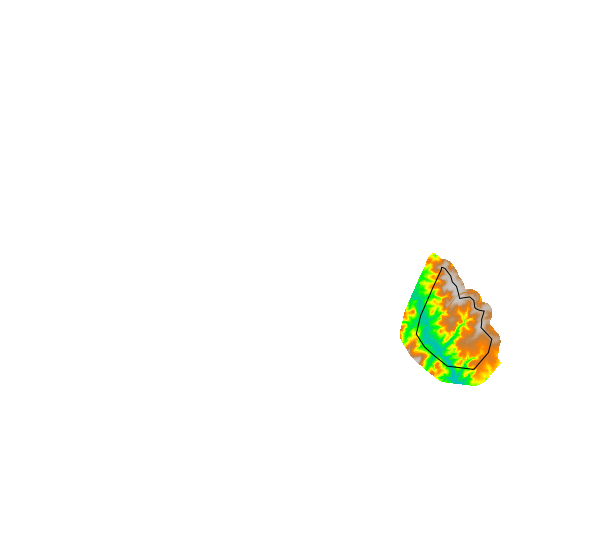

In [25]:
# Initialize the map object 
ms = gj.Map()

# Add raster and vector layers
ms.d_rast(map=dem)
ms.d_vect(map=basins, color="black",fill_color ='None')

# Display the final plot
ms.show()

In [26]:
m = gj.InteractiveMap(height=600,width=1200)
m.add_vector(basins+'_buffer')
m.add_raster(dem,opacity=0.7)
m.show()

Map(center=[0.0, 0.0], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_out_t…

In [57]:
carved = False

In [22]:
grass_maps = list_existing_grass()

In [39]:
dem

'dem_020402020602_b'

In [25]:
dem = 'dem_'+str(select_data)
if carved:
    if c_lines+'@PERMANENT' not in grass_maps['vector']:
        gs.run_command('v.import', input= carve_lines,extent='region', output= c_lines)
    gs.run_command('r.carve',raster=dem,vector = c_lines, output= dem+'_b', flags='n', width = 2*cell_size,depth=0)
    dem+='_b'

## Create Stream Network

In [41]:
gs.run_command('r.watershed', elevation=dem,threshold = threshold//(cell_size**2),accumulation=accum,basin=sub_basins,tci=twi,flags='sab')

In [42]:
gs.run_command('r.stream.extract',elevation=dem,threshold = threshold//(cell_size**2),accumulation=accum,direction=drain_dir,stream_raster=r_streams,stream_vector=v_streams)

In [43]:
## Export
#gs.run_command('r.out.gdal', input= twi, output= raster_dir/f'{twi}.tif',createopt="BIGTIFF=YES,PROFILE=GeoTIFF,TFW=YES,COMPRESS=LZW",flags='f')
#gs.run_command('r.out.gdal', input= dem, output= raster_dir/f'{dem}.tif',createopt="BIGTIFF=YES,PROFILE=GeoTIFF,TFW=YES,COMPRESS=LZW",flags='f')
gs.run_command('v.out.ogr',input=v_streams,output=vector_dir/f'{v_streams}.geojson',type= 'line',format='GeoJSON')

In [44]:
#convert to shp
#TODO add v.clean to code.
gpd.read_file(vector_dir/f'{v_streams}.geojson').to_file(vector_dir/f'v_{v_streams}.shp')

/tmp/ipykernel_745/1453846685.py:3: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gpd.read_file(vector_dir/f'{v_streams}.geojson').to_file(vector_dir/f'v_{v_streams}.shp')
/opt/conda/envs/grassenv/lib/python3.12/site-packages/pyogrio/raw.py:733: RuntimeWarning: Normalized/laundered field name: 'stream_type' to 'stream_typ'
  ogr_write(


## END